# Car Racing Agent: A* heuristic comparison (Deliverable 2)

**CSE518 Artificial Intelligence, Project Part 1**

This notebook compares the heuristics used by the A* path planner of the car racing agent.
The car drives on a 4-connected grid. The cost of a move depends on the tile being entered
(asphalt 2, grass 6, wall impassable) **and on the direction of travel**. Moving with a
slope/current costs half, moving against it costs double. Costs are therefore **asymmetric**.

| id | heuristic | idea |
|----|-----------|------|
| h0 | Zero (Dijkstra) | baseline, reference optimal costs |
| **h1** | Manhattan × c_min | every remaining move costs at least the cheapest move on the map |
| **h2** | Euclidean × c_min | straight-line distance, weaker than Manhattan on a 4-grid |
| **h3** | Row/column corridor bound | cheapest way to *enter* every row/column between n and the goal, using terrain and currents |
| **h4** | ALT landmarks | triangle-inequality bounds from exact distances to/from 6 landmarks (directed version) |
| h5 | Weighted A* (2·h3) | bonus: inadmissible, shows the speed/optimality trade-off |

h1–h4 are the four heuristics we designed. h0 is the reference and h5 is an extra.

**Contents**
1. Setup and maps
2. Admissibility and consistency check (empirical)
3. Experiment A: all ordered pairs on the course map and the racing track
4. Experiment B: 60 random maps in three sizes
5. Experiment C: where does A* search? (expansion heat maps)
6. Experiment D: informedness h/h*
7. Experiment E: full missions (reflex + A*)
8. Conclusions

In [1]:
import sys, time, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
from matplotlib.patches import Patch

from src.world import load_map, WALL, GRASS
from src.search import astar
from src.heuristics import HEURISTIC_INFO
from src import experiments as X

FIG = ROOT / "report" / "figures"; FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#b5b3ad", "axes.grid": True, "grid.color": "#e6e4de",
    "grid.linewidth": 0.7, "axes.axisbelow": True, "axes.titleweight": "bold",
    "axes.titlesize": 11, "legend.frameon": False,
})
pd.set_option("display.width", 160, "display.max_columns", 30)
COL = X.PALETTE
main = load_map(ROOT / "maps/map_main.txt")
track = load_map(ROOT / "maps/track_main.txt")
for g in (main, track):
    print(f"{g.name:11s} {g.rows}x{g.cols}  capacity={g.capacity}  checkpoints={list(g.sites)}  "
          f"refuel points={g.pits}  c_min={g.min_step_cost}")

map_main    15x20  capacity=50  checkpoints=[1, 2, 3, 4, 5]  refuel points=[(13, 1), (1, 11), (11, 16)]  c_min=1
track_main  16x26  capacity=70  checkpoints=[1, 2, 3, 4, 5, 6]  refuel points=[(1, 1), (7, 1), (11, 24)]  c_min=1


## 1. Maps
Gray = asphalt (2), green = grass (6), black = wall, arrows = slope/current.

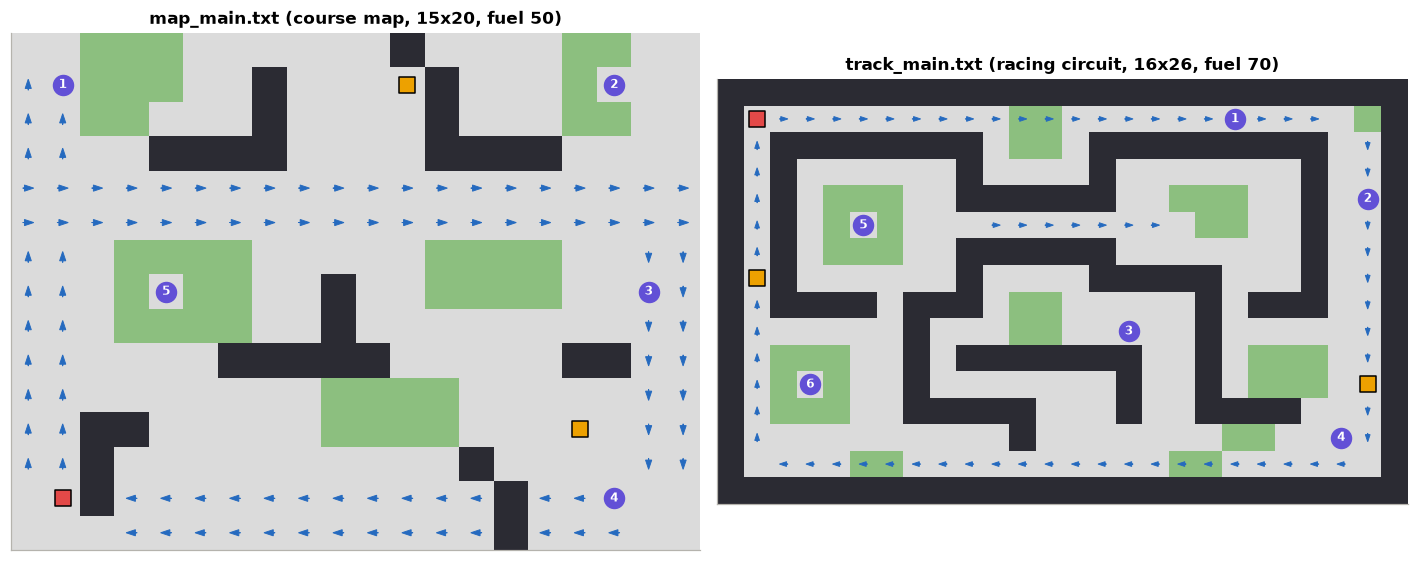

In [2]:
def draw_map(g, ax, path=None, title=None, overlay=None, cmap=None):
    img = np.ones((g.rows, g.cols, 3))
    for r in range(g.rows):
        for c in range(g.cols):
            t = g.terrain[r][c]
            img[r, c] = (0.17,0.17,0.2) if t == WALL else (0.55,0.75,0.5) if t == GRASS else (0.86,0.86,0.86)
    ax.imshow(img, interpolation="nearest")
    if overlay is not None:
        ax.imshow(overlay, cmap=cmap, interpolation="nearest", alpha=0.85)
    arrow = {"N":(0,-0.32),"S":(0,0.32),"E":(0.32,0),"W":(-0.32,0)}
    for r in range(g.rows):
        for c in range(g.cols):
            d = g.current[r][c]
            if d: ax.arrow(c-arrow[d][0]/2, r-arrow[d][1]/2, arrow[d][0], arrow[d][1],
                           head_width=0.18, length_includes_head=True, color="#256abf", lw=0.6)
    if path:
        ax.plot([p[1] for p in path], [p[0] for p in path], color="#e34948", lw=2)
    ax.scatter(*g.home[::-1], marker="s", s=120, c="#e34948", edgecolors="k", zorder=5)
    for P in g.pits[1:]:
        ax.scatter(P[1], P[0], marker="s", s=120, c="#eda100", edgecolors="k", zorder=5)
    for k, p in g.sites.items():
        ax.scatter(p[1], p[0], s=170, c="#6250d6", zorder=5)
        ax.text(p[1], p[0], str(k), color="w", ha="center", va="center", fontsize=8, weight="bold", zorder=6)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    if title: ax.set_title(title)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
draw_map(main, axes[0], title="map_main.txt (course map, 15x20, fuel 50)")
draw_map(track, axes[1], title="track_main.txt (racing circuit, 16x26, fuel 70)")
plt.tight_layout(); plt.savefig(FIG / "maps.png", bbox_inches="tight"); plt.show()

## 2. Admissibility and consistency check

For every tile *n* and several goals we compute the exact cost-to-go *h\*(n)* with a reverse
Dijkstra. Then we count how often **h(n) > h\*(n)** (admissibility violated) and how often
**h(n) > c(n,n') + h(n')** (consistency violated).

In [3]:
rows = []
for g in (main, track):
    goals = list(X.key_points(g).values())[:6]
    inf = X.informedness(g)
    for h in ["h1","h2","h3","h4","h5"]:
        rows.append(dict(map=g.name, heuristic=h, description=HEURISTIC_INFO[h],
                         overestimates=int(inf.loc[h,"overestimates"]),
                         admissible=bool(inf.loc[h,"admissible"]),
                         consistency_violations=X.consistency_violations(g, h, goals)))
adm = pd.DataFrame(rows)
adm["consistent"] = adm.consistency_violations == 0
adm

,map,heuristic,description,overestimates,admissible,consistency_violations,consistent
0,map_main,h1,Manhattan x c_min,0,True,0,True
1,map_main,h2,Euclidean x c_min,0,True,0,True
2,map_main,h3,Row/Column corridor bound,0,True,0,True
3,map_main,h4,ALT landmarks,0,True,0,True
4,map_main,h5,"Weighted A* (2 x h3, inadmissible)",984,False,957,False
5,track_main,h1,Manhattan x c_min,0,True,0,True
6,track_main,h2,Euclidean x c_min,0,True,0,True
7,track_main,h3,Row/Column corridor bound,0,True,0,True
8,track_main,h4,ALT landmarks,0,True,0,True
9,track_main,h5,"Weighted A* (2 x h3, inadmissible)",496,False,312,False


h1–h4 have **zero** violations on both maps, so they are admissible and consistent, and A* with any of
them returns optimal paths. h5 (2·h3) over-estimates on many tiles, so it is **not** admissible.

## 3. Experiment A: every ordered pair of key points
Key points = H, all checkpoints and all pit stops. Each ordered pair (A→B and B→A are different
because of the currents) is solved with every heuristic.

In [4]:
dfA = pd.concat([X.pairwise_runs(main), X.pairwise_runs(track)], ignore_index=True)
sumA = {m: X.summarise(dfA[dfA["map"] == m]) for m in ["map_main", "track_main"]}
print("map_main"); display(sumA["map_main"])
print("track_main"); display(sumA["track_main"])

map_main


,description,searches,total_expanded,mean_expanded,mean_ms,mean_ebf,optimal_pct,max_gap_pct,expanded_vs_dijkstra
heuristic,,,,,,,,,
h0,Zero / Dijkstra (baseline),56,8792,157.000,0.754,1.270,100.000,0.00,1.000
h1,Manhattan x c_min,56,4737,84.589,0.495,1.148,100.000,0.00,0.539
h2,Euclidean x c_min,56,5729,102.304,0.554,1.178,100.000,0.00,0.652
h3,Row/Column corridor bound,56,4042,72.179,0.381,1.132,100.000,0.00,0.460
h4,ALT landmarks,56,1545,27.589,0.261,1.042,100.000,0.00,0.176
h5,"Weighted A* (2 x h3, inadmissible)",56,2171,38.768,0.274,1.070,57.143,56.25,0.247


track_main


,description,searches,total_expanded,mean_expanded,mean_ms,mean_ebf,optimal_pct,max_gap_pct,expanded_vs_dijkstra
heuristic,,,,,,,,,
h0,Zero / Dijkstra (baseline),72,9701,134.736,0.675,1.174,100.000,0.000,1.000
h1,Manhattan x c_min,72,6480,90.000,0.409,1.104,100.000,0.000,0.668
h2,Euclidean x c_min,72,7227,100.375,0.511,1.118,100.000,0.000,0.745
h3,Row/Column corridor bound,72,5887,81.764,0.411,1.098,100.000,0.000,0.607
h4,ALT landmarks,72,2232,31.000,0.286,1.026,100.000,0.000,0.230
h5,"Weighted A* (2 x h3, inadmissible)",72,4520,62.778,0.314,1.074,41.667,36.538,0.466


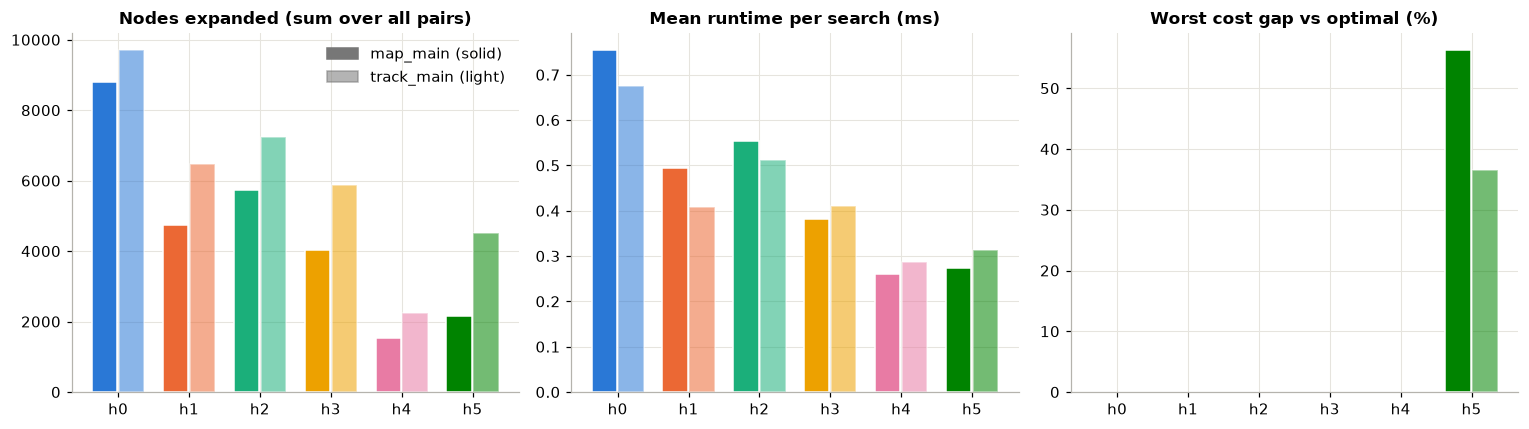

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
labels = X.HEURS
for ax, (metric, title) in zip(axes, [("total_expanded", "Nodes expanded (sum over all pairs)"),
                                       ("mean_ms", "Mean runtime per search (ms)"),
                                       ("max_gap_pct", "Worst cost gap vs optimal (%)")]):
    w = 0.38
    x = np.arange(len(labels))
    for j, m in enumerate(["map_main", "track_main"]):
        vals = sumA[m].loc[labels, metric].values
        bars = ax.bar(x + (j - 0.5) * w, vals, w * 0.94, color=[COL[h] for h in labels],
                      alpha=1.0 if j == 0 else 0.55, edgecolor="white", linewidth=1)
    ax.set_xticks(x, labels); ax.set_title(title)
axes[0].legend(handles=[Patch(color="#777", alpha=1.0, label="map_main (solid)"),
                        Patch(color="#777", alpha=0.55, label="track_main (light)")], loc="upper right")
plt.tight_layout(); plt.savefig(FIG / "expA_bars.png", bbox_inches="tight"); plt.show()

## 4. Experiment B: 60 random maps (12×16, 20×30, 30×40)
Random terrain (18 % walls, 15 % grass), straight current lanes, 5 checkpoints and several pits.

In [6]:
t0 = time.perf_counter()
suite = X.random_suite(60)
dfB = X.suite_runs(suite)
print(f"{len(dfB)} searches on {len(suite)} maps in {time.perf_counter()-t0:.1f}s")
sumB = X.summarise(dfB); sumB

28560 searches on 60 maps in 25.6s


,description,searches,total_expanded,mean_expanded,mean_ms,mean_ebf,optimal_pct,max_gap_pct,expanded_vs_dijkstra
heuristic,,,,,,,,,
h0,Zero / Dijkstra (baseline),4760,1531529,321.750,1.547,1.320,100.000,0.000,1.000
h1,Manhattan x c_min,4760,891953,187.385,0.941,1.203,100.000,0.000,0.582
h2,Euclidean x c_min,4760,1031045,216.606,1.079,1.221,100.000,0.000,0.673
h3,Row/Column corridor bound,4760,424029,89.082,0.475,1.119,100.000,0.000,0.277
h4,ALT landmarks,4760,156423,32.862,0.306,1.046,100.000,0.000,0.102
h5,"Weighted A* (2 x h3, inadmissible)",4760,147893,31.070,0.177,1.053,49.811,66.667,0.097


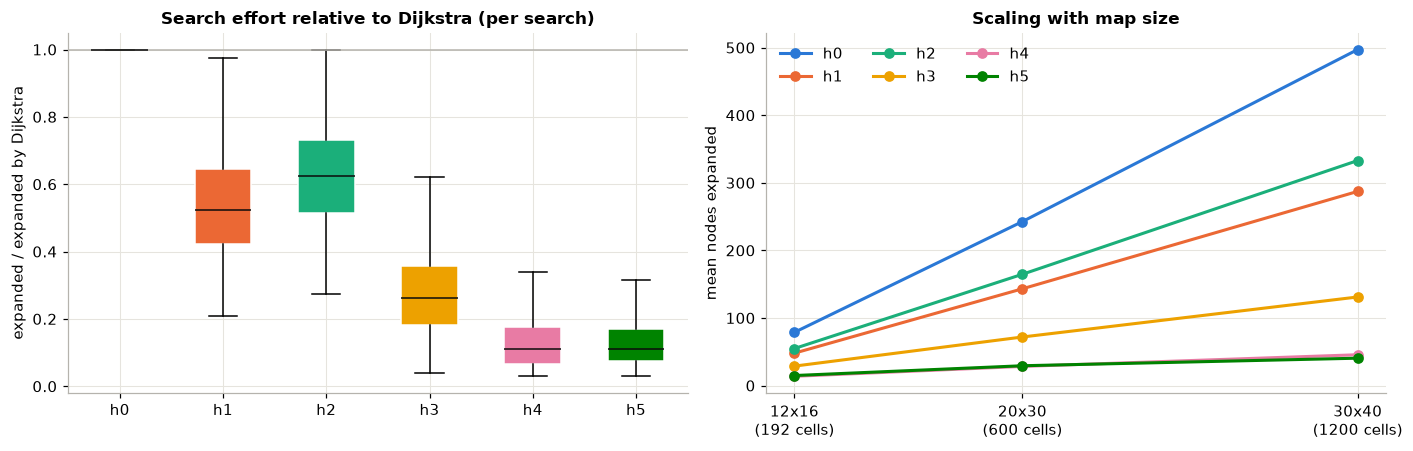

heuristic,h0,h1,h2,h3,h4,h5
size,,,,,,
12x16,78.8,48.0,54.8,28.8,13.7,14.8
20x30,242.7,143.2,164.7,71.8,28.3,29.3
30x40,497.2,287.3,333.0,131.1,45.6,40.5


In [7]:
by_size = dfB.groupby(["size", "heuristic"]).expanded.mean().unstack()
by_size = by_size.loc[sorted(by_size.index, key=lambda s: int(s.split('x')[0])*int(s.split('x')[1]))]
rel = dfB.pivot_table(index=["map","start","goal"], columns="heuristic", values="expanded")
rel = rel.div(rel["h0"], axis=0)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
ax = axes[0]
bp = ax.boxplot([rel[h].values for h in X.HEURS], tick_labels=X.HEURS, patch_artist=True,
                showfliers=False, widths=0.55, medianprops=dict(color="#0b0b0b"))
for patch, h in zip(bp["boxes"], X.HEURS):
    patch.set_facecolor(COL[h]); patch.set_edgecolor("white")
ax.set_ylabel("expanded / expanded by Dijkstra"); ax.set_title("Search effort relative to Dijkstra (per search)")
ax.axhline(1, color="#b5b3ad", lw=1)

ax = axes[1]
xs = [int(s.split('x')[0])*int(s.split('x')[1]) for s in by_size.index]
for h in X.HEURS:
    ax.plot(xs, by_size[h].values, marker="o", ms=6, lw=2, color=COL[h], label=h)
ax.set_xticks(xs, [f"{s}\n({x} cells)" for s, x in zip(by_size.index, xs)])
ax.set_ylabel("mean nodes expanded"); ax.set_title("Scaling with map size")
ax.legend(ncol=3, loc="upper left")
plt.tight_layout(); plt.savefig(FIG / "expB_box_scaling.png", bbox_inches="tight"); plt.show()
by_size.round(1)

## 5. Experiment C: where does each heuristic search?
Cells expanded by A* for the leg **H → checkpoint 2** on the course map. Darker = expanded.
The red line is the optimal path.

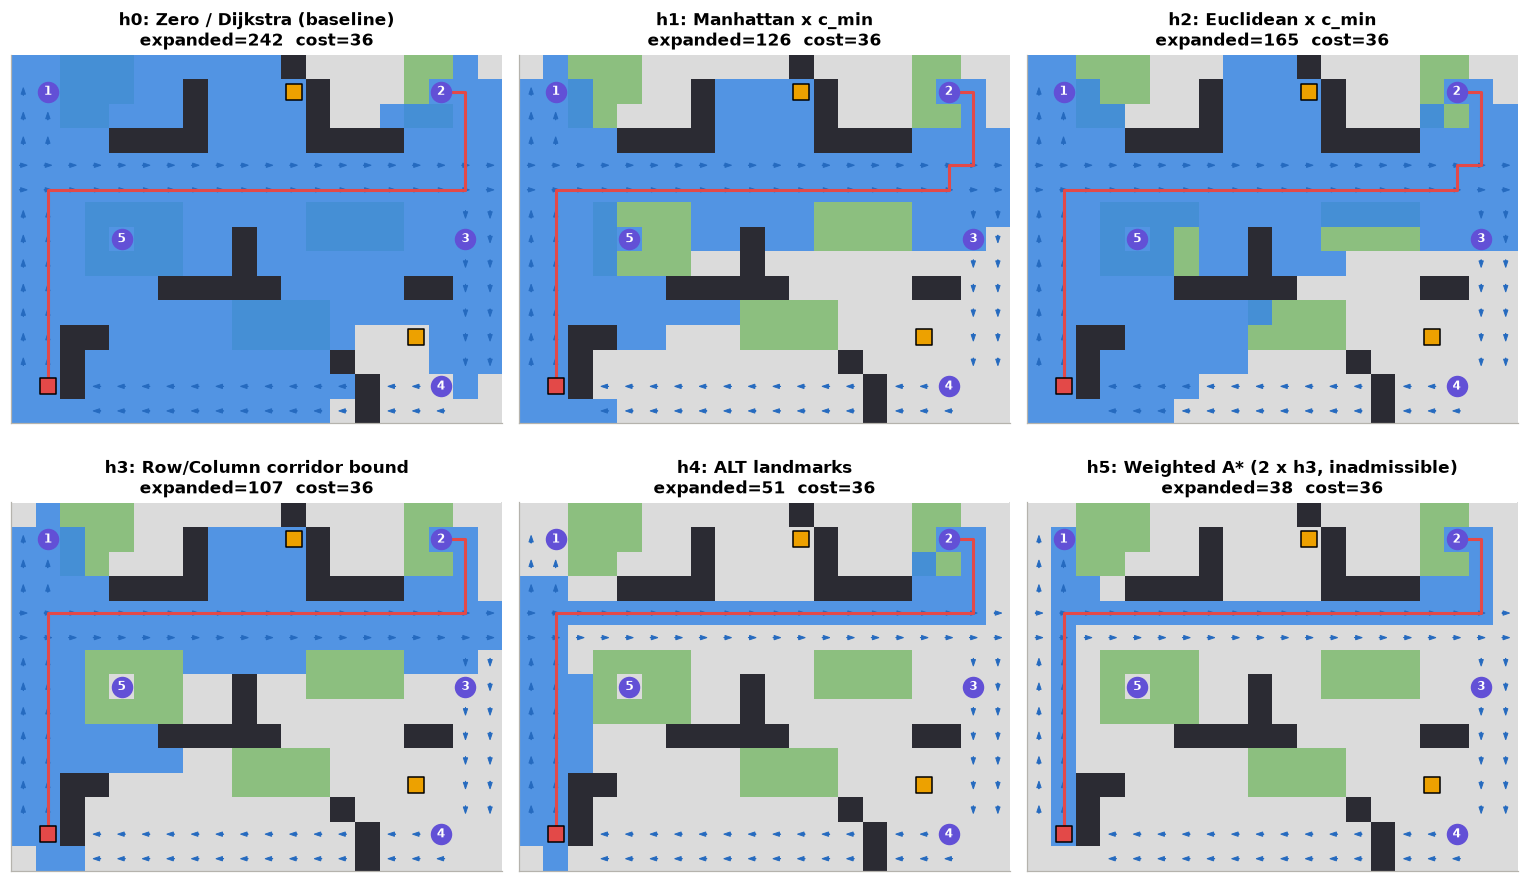

In [8]:
start, goal = main.home, main.sites[2]
fig, axes = plt.subplots(2, 3, figsize=(14, 8.6))
cmap = ListedColormap(["#00000000", "#3987e5"])
for ax, h in zip(axes.ravel(), X.HEURS):
    r = astar(main, start, goal, h, keep_expanded=True)
    ov = np.zeros((main.rows, main.cols))
    for p in r.expanded: ov[p] = 1
    ov = np.ma.masked_where(ov == 0, ov)
    draw_map(main, ax, path=r.path, overlay=ov, cmap=ListedColormap(["#3987e5"]),
             title=f"{h}: {HEURISTIC_INFO[h]}\nexpanded={r.nodes_expanded}  cost={r.cost:g}")
plt.tight_layout(); plt.savefig(FIG / "expC_heatmaps.png", bbox_inches="tight"); plt.show()

## 6. Experiment D: informedness
Mean ratio h(n)/h\*(n) over all tiles and several goals. 1.0 is a perfect heuristic. A higher
ratio means fewer expansions, as long as it never goes above 1 (admissibility).

,map,heuristic,mean_h_over_hstar,min_ratio,max_ratio,overestimates,admissible
0,map_main,h1,0.512,0.154,1.0,0,True
1,map_main,h2,0.412,0.142,1.0,0,True
2,map_main,h3,0.605,0.174,1.0,0,True
3,map_main,h4,0.912,0.000,1.0,0,True
4,map_main,h5,1.210,0.348,2.0,984,False
5,track_main,h1,0.411,0.036,1.0,0,True
6,track_main,h2,0.333,0.036,1.0,0,True
7,track_main,h3,0.460,0.054,1.0,0,True
8,track_main,h4,0.942,0.000,1.0,0,True
9,track_main,h5,0.920,0.107,2.0,496,False


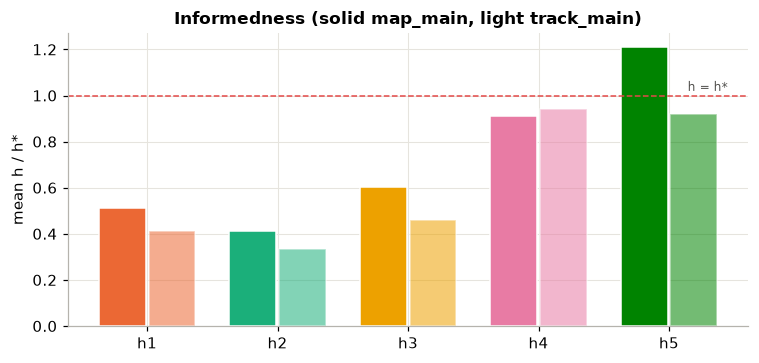

In [9]:
inf = pd.concat({g.name: X.informedness(g) for g in (main, track)}, names=["map"]).reset_index()
display(inf)
fig, ax = plt.subplots(figsize=(7, 3.4))
hs = ["h1","h2","h3","h4","h5"]; x = np.arange(len(hs)); w = 0.38
for j, m in enumerate(["map_main", "track_main"]):
    v = inf[inf["map"] == m].set_index("heuristic").loc[hs, "mean_h_over_hstar"]
    ax.bar(x + (j-0.5)*w, v, w*0.94, color=[COL[h] for h in hs], alpha=1 if j == 0 else 0.55, edgecolor="white")
ax.axhline(1, color="#e34948", lw=1, ls="--"); ax.text(4.45, 1.02, "h = h*", color="#52514e", fontsize=8, ha="right")
ax.set_xticks(x, hs); ax.set_ylabel("mean h / h*"); ax.set_title("Informedness (solid map_main, light track_main)")
plt.tight_layout(); plt.savefig(FIG / "expD_informedness.png", bbox_inches="tight"); plt.show()

**Pre-computation cost of h4 (ALT).** The landmark tables (2 Dijkstra runs per landmark) are built
once per map and reused by every later search:

In [10]:
pre = pd.DataFrame([dict(map=g.name, cells=g.rows*g.cols, alt_precompute_ms=round(X.alt_precompute_ms(g), 2))
                    for g in [main, track] + suite[:3]])
pre

,map,cells,alt_precompute_ms
0,map_main,300,21.02
1,track_main,416,18.50
2,rand00_12x16,192,11.47
3,rand01_20x30,600,32.77
4,rand02_30x40,1200,54.96


## 7. Experiment E: full missions (reflex module + tour planner + A*)
Each run uses a fresh copy of the map, so the ALT pre-computation is included in the time.
The agent applies all four fuel rules (R1–R4), re-plans after every pit stop and
returns to H.

In [11]:
mis = X.mission_table({"map_main": main, "track_main": track})
mis

,map,mode,heuristic,status,fuel_used,moves,pit_stops,replans,planned_tour_cost,searches,nodes_expanded,search_ms,total_ms,visit_order,violations
0,map_main,survey,h0,DONE,232.0,138,4,4,126,49,6020,29.19,47.5,5-1-2-3-4,0
1,map_main,survey,h1,DONE,232.0,138,4,4,126,49,3285,17.02,35.2,5-1-2-3-4,0
2,map_main,survey,h2,DONE,232.0,138,4,4,126,49,3933,22.28,40.8,5-1-2-3-4,0
3,map_main,survey,h3,DONE,232.0,138,4,4,126,49,2777,18.14,34.7,5-1-2-3-4,0
4,map_main,survey,h4,DONE,232.0,138,4,4,126,49,1152,13.60,45.3,5-1-2-3-4,0
5,map_main,survey,h5,DONE,224.0,126,4,4,126,53,2374,13.10,34.3,1-2-3-4-5,0
6,map_main,race,h0,DONE,179.0,106,3,3,138,32,2962,15.15,31.5,1-2-3-4-5,0
7,map_main,race,h1,DONE,179.0,106,3,3,138,32,1462,7.54,22.4,1-2-3-4-5,0
8,map_main,race,h2,DONE,179.0,106,3,3,138,32,1816,9.43,24.6,1-2-3-4-5,0
9,map_main,race,h3,DONE,179.0,106,3,3,138,32,1280,7.06,20.2,1-2-3-4-5,0


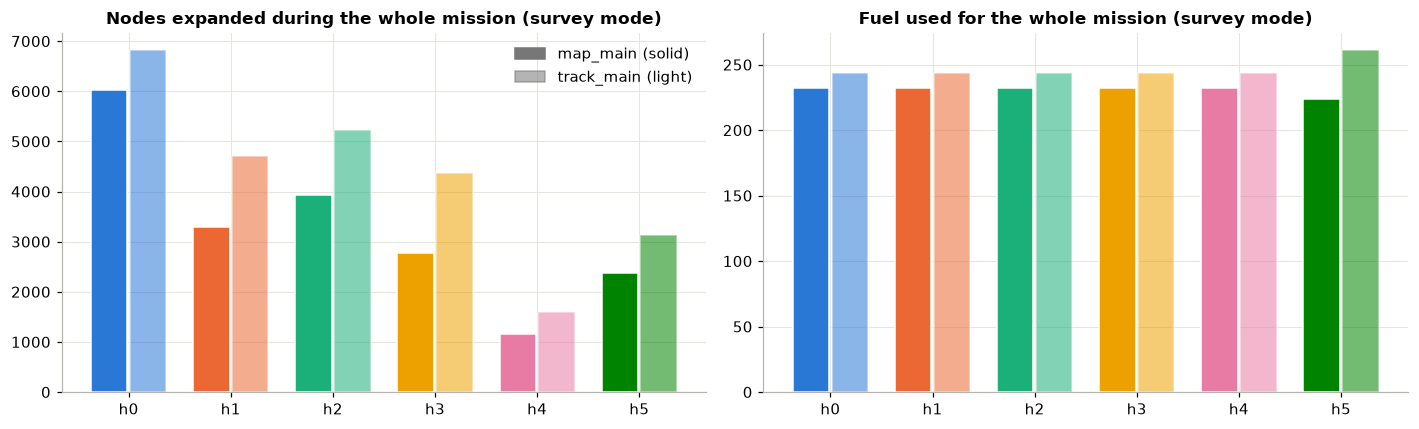

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, metric, title in [(axes[0], "nodes_expanded", "Nodes expanded during the whole mission"),
                          (axes[1], "fuel_used", "Fuel used for the whole mission")]:
    sub = mis[mis["mode"] == "survey"]
    x = np.arange(len(X.HEURS)); w = 0.38
    for j, m in enumerate(["map_main", "track_main"]):
        v = sub[sub["map"] == m].set_index("heuristic").loc[X.HEURS, metric]
        ax.bar(x + (j-0.5)*w, v, w*0.94, color=[COL[h] for h in X.HEURS], alpha=1 if j == 0 else 0.55, edgecolor="white")
    ax.set_xticks(x, X.HEURS); ax.set_title(title + " (survey mode)")
axes[0].legend(handles=[Patch(color="#777", label="map_main (solid)"), Patch(color="#777", alpha=0.55, label="track_main (light)")])
plt.tight_layout(); plt.savefig(FIG / "expE_missions.png", bbox_inches="tight"); plt.show()

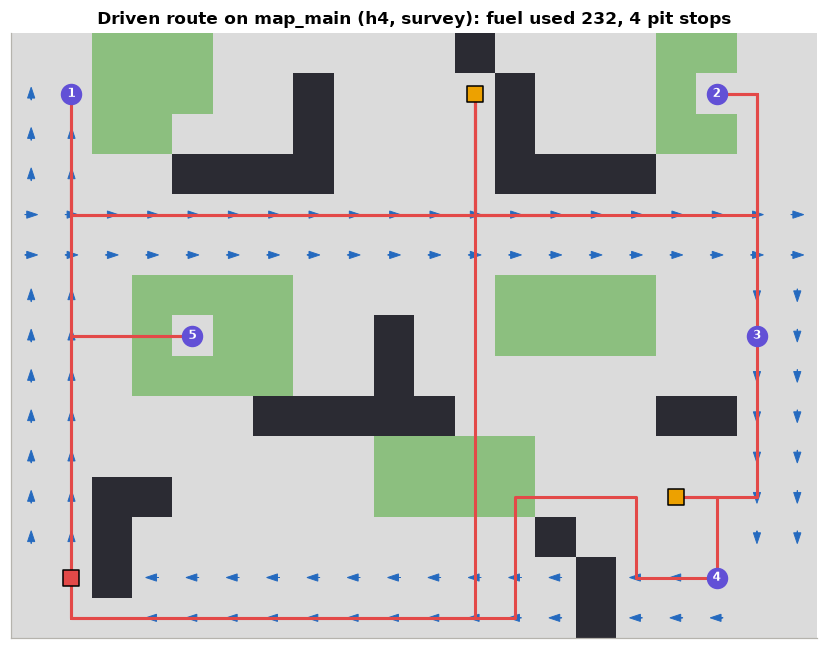

[map_main | h4 | survey] status=DONE moves=138 fuel_used=232 pit_stops=4 replans=4 order=[5, 1, 2, 3, 4] skipped=[] planned_tour_cost=126 searches=49 nodes_expanded=1152 min_fuel=0 violations=0
  rules fired: R0:1, R1:4, R2:1, R3:2, R4:1, R6:5, R7:139


,t,pos,fuel,rule,action,note
0,10,"(7, 4)",34,R6,MARK_CHECKPOINT,checkpoint 5 cleared
1,18,"(3, 1)",18,R3,GOTO_PIT,"heading to pit (1, 11)"
2,33,"(1, 11)",50,R1,REFUEL,refuel 0 -> 50
3,58,"(13, 1)",50,R1,REFUEL,refuel 2 -> 50
4,71,"(1, 1)",36,R6,MARK_CHECKPOINT,checkpoint 1 cleared
5,72,"(1, 1)",36,R7,REPLAN,"plan finished, re-planning remaining tour"
6,88,"(4, 13)",14,R3,GOTO_PIT,"heading to pit (1, 11)"
7,94,"(1, 11)",50,R1,REFUEL,refuel 0 -> 50
8,109,"(1, 17)",29,R6,MARK_CHECKPOINT,checkpoint 2 cleared
9,117,"(7, 18)",17,R6,MARK_CHECKPOINT,checkpoint 3 cleared


In [13]:
from src.agent import run_mission
r = run_mission(main, "h4", "survey")
fig, ax = plt.subplots(figsize=(8, 6))
draw_map(main, ax, path=r.path, title=f"Driven route on map_main (h4, survey): fuel used {r.fuel_used:g}, {r.pit_stops} pit stops")
plt.tight_layout(); plt.savefig(FIG / "route_main.png", bbox_inches="tight"); plt.show()
print(r.summary())
events = pd.DataFrame([dict(t=e.t, pos=e.pos, fuel=e.fuel, rule=e.rule, action=e.action, note=e.note)
                       for e in r.log if e.action != "MOVE"])
events

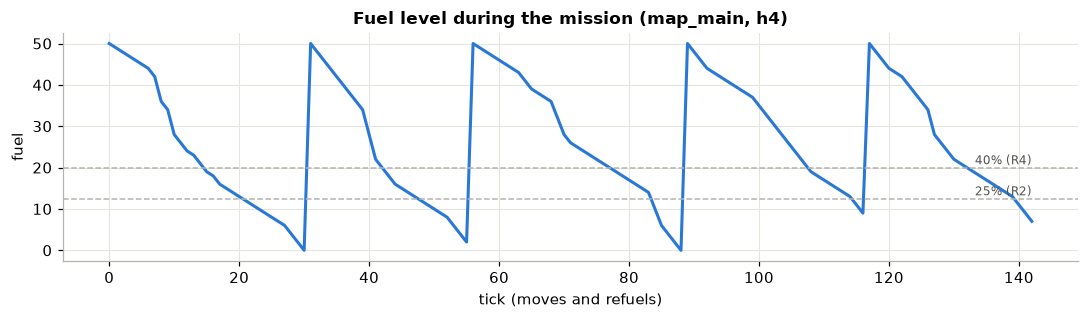

In [14]:
# Fuel over time with refuel events (shows the 25% / 40% thresholds)
fuel = [main.capacity] + [e.fuel for e in r.log if e.action in ("MOVE", "REFUEL")]
fig, ax = plt.subplots(figsize=(10, 3))
ax.plot(fuel, color=COL["h0"], lw=2)
for th, lab in [(0.25, "25% (R2)"), (0.40, "40% (R4)")]:
    ax.axhline(th*main.capacity, color="#b5b3ad", ls="--", lw=1)
    ax.text(len(fuel)-1, th*main.capacity+0.8, lab, ha="right", fontsize=8, color="#52514e")
ax.set_xlabel("tick (moves and refuels)"); ax.set_ylabel("fuel"); ax.set_title("Fuel level during the mission (map_main, h4)")
plt.tight_layout(); plt.savefig(FIG / "fuel_trace.png", bbox_inches="tight"); plt.show()

In [15]:
# numbers quoted in the report
summary = {
  "A_main": sumA["map_main"][["total_expanded","expanded_vs_dijkstra","mean_ms","mean_ebf","optimal_pct","max_gap_pct"]],
  "B_random": sumB[["total_expanded","expanded_vs_dijkstra","mean_ms","mean_ebf","optimal_pct","max_gap_pct"]],
}
for k, v in summary.items():
    print(k); print(v.to_string()); print()
sumA["map_main"].to_csv(FIG / "expA_main_summary.csv"); sumA["track_main"].to_csv(FIG / "expA_track_summary.csv")
sumB.to_csv(FIG / "expB_summary.csv"); mis.to_csv(FIG / "expE_missions.csv", index=False); adm.to_csv(FIG / "admissibility.csv", index=False)
inf.to_csv(FIG / "informedness.csv", index=False); by_size.to_csv(FIG / "expB_by_size.csv")

A_main
           total_expanded  expanded_vs_dijkstra  mean_ms  mean_ebf  optimal_pct  max_gap_pct
heuristic                                                                                   
h0                   8792                 1.000    0.754     1.270      100.000         0.00
h1                   4737                 0.539    0.495     1.148      100.000         0.00
h2                   5729                 0.652    0.554     1.178      100.000         0.00
h3                   4042                 0.460    0.381     1.132      100.000         0.00
h4                   1545                 0.176    0.261     1.042      100.000         0.00
h5                   2171                 0.247    0.274     1.070       57.143        56.25

B_random
           total_expanded  expanded_vs_dijkstra  mean_ms  mean_ebf  optimal_pct  max_gap_pct
heuristic                                                                                   
h0                1531529                 1.000    1.

## 8. Conclusions

* **All four designed heuristics (h1–h4) are admissible and consistent.** This is proven in the report
  and confirmed above with zero violations. They always return the same optimal cost as Dijkstra.
  Only the search effort changes.
* **Ranking by search effort: h4 (ALT) < h3 (corridor) < h1 (Manhattan) < h2 (Euclidean) < h0.**
  Euclidean is the weakest informed heuristic because on a 4-connected grid it is always ≤ Manhattan.
* **h3** reads terrain and currents. It is never weaker than h1 and is clearly better wherever whole rows
  or columns can only be entered expensively (grass bands, headwinds). It costs O(1) per call after an
  O(cells) pre-pass.
* **h4 (ALT)** is the most informed by far (mean h/h\* = 0.91 on map_main, 0.94 on the track). It expands
  **4–10× fewer nodes than Dijkstra** (17.6 % on map_main, 23 % on the track, 10 % on the random maps),
  because the landmark distances already contain the walls and the asymmetric currents. Its price is a one-off
  pre-computation (2 Dijkstra runs per landmark, a few ms). It pays off because the tour planner runs
  dozens of searches on the same map.
* **h3** is never weaker than h1 (each row/column entry costs ≥ c_min). It gains most on the random maps
  (28 % of Dijkstra's expansions vs 58 % for h1), where walls and grass make whole rows expensive to enter.
* **h5 (weighted)** expands about as few nodes as ALT on random maps, but is optimal in only ~50 % of
  searches (worst gap 67 %). It is useful only when planning time matters more than fuel.
* **Mission level:** every admissible heuristic gives the same tour cost. The small fuel differences
  (e.g. 283 vs 310 on the track in race mode) come only from tie-breaking between equal-cost paths,
  which changes where the fuel rules fire.
* **Interesting finding:** on map_main the fuel-agnostic optimal tour (survey, planned cost 126) uses
  **more** fuel in practice (232) than the fixed race order 1→5 (planned 138, actual 179), because it sends
  the car to checkpoints far from any pit, and then the reflex rules add long detours. A
  **fuel-aware tour planner** (tour cost evaluated with pit stops) is therefore the main improvement for Part 2.

**Recommendation:** use **h4 (ALT)** as the default planner heuristic, and **h3** when pre-computation is
not possible (e.g. maps that change online).